<a href="https://colab.research.google.com/github/eternitvy/ML_26/blob/main/JS08/JS08_TUGAS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None

Lima Data Teratas:
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6 

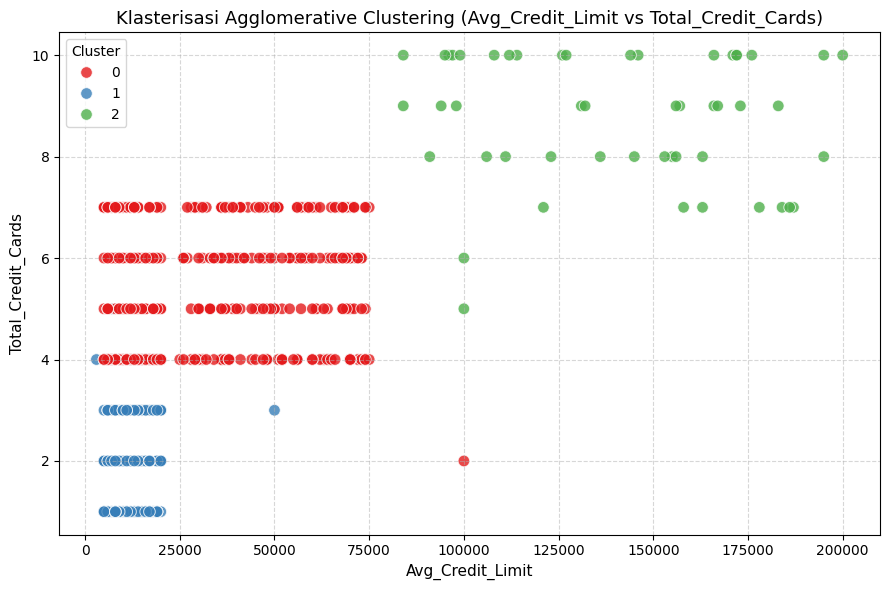


Rata-rata Fitur per Klaster:
         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster                                                            
0            33851.948052            5.516883           3.493506   
1            12151.111111            2.422222           0.937778   
2           141040.000000            8.740000           0.600000   

         Total_visits_online  Total_calls_made  
Cluster                                         
0                   0.979221          1.994805  
1                   3.546667          6.857778  
2                  10.900000          1.080000  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Memuat Dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Menampilkan informasi awal dataset
print("Informasi Dataset:")
print(df.info())
print("\nLima Data Teratas:")
print(df.head())

# 2. Menentukan Fitur (Mengabaikan kolom ID seperti Sl_No dan Customer Key)
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made',
]
X = df[features]

# 3. Standarisasi Fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Membuat Model Agglomerative Clustering (Jumlah klaster optimal k = 3)
k = 3
model = AgglomerativeClustering(n_clusters=k)
df['Cluster'] = model.fit_predict(X_scaled)

# 5. Evaluasi Model (Silhouette Score & Davies-Bouldin Index)
sil_score = silhouette_score(X_scaled, df['Cluster'])
dbi_score = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"\n--- Hasil Evaluasi Model (k={k}) ---")
print(f"Silhouette Score          : {sil_score:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")

# 6. Visualisasi Scatterplot (Avg_Credit_Limit vs Total_Credit_Cards)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='Set1',
    s=70,
    alpha=0.8,
)

plt.title(
    'Klasterisasi Agglomerative Clustering (Avg_Credit_Limit vs'
    ' Total_Credit_Cards)',
    fontsize=13,
)
plt.xlabel('Avg_Credit_Limit', fontsize=11)
plt.ylabel('Total_Credit_Cards', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster')
plt.tight_layout()

# Menyimpan gambar plot
plt.savefig('scatter_cluster.png', dpi=300)
print(
    '\nPlot berhasil disimpan ke file "scatter_cluster.png". Menampilkan'
    ' plot...'
)
plt.show()

# 7. Rata-rata Karakteristik per Klaster
print('\nRata-rata Fitur per Klaster:')
print(df.groupby('Cluster')[features].mean())